Pre-processing step that allows to inspect the quality of the raw data. 

In [59]:
import sys
import importlib.util
from pathlib import Path

# Load custom io module explicitly to avoid shadowing stdlib io
io_path = Path('../src/io.py').resolve()
spec = importlib.util.spec_from_file_location('custom_io', io_path)
custom_io = importlib.util.module_from_spec(spec)
spec.loader.exec_module(custom_io)
load_onix_recording = custom_io.load_onix_recording

import numpy as np
import matplotlib.pyplot as plt
import spikeinterface.full as si
import yaml

try:
    from IPython import get_ipython
    ip = get_ipython()
except Exception:
    ip = None

if ip is not None:
    try:
        ip.run_line_magic('autoreload', '2')
    except Exception:
        pass

    try:
        ip.run_line_magic('matplotlib', 'widget')
    except Exception:
        ip.run_line_magic('matplotlib', 'inline')

In [60]:
with open('../config.yml') as f:
    cfg = yaml.safe_load(f)

prb = cfg['probe']
acq = cfg['acquisition']
paths = cfg['paths']

In [61]:
recording = load_onix_recording(
    raw_dir=paths['raw_dir'],
    probe_name=prb['model'],
    sampling_frequency=acq['sampling_frequency'],
    n_channels=acq['n_channels'],
    dtype=acq['dtype'],
)

Found 1 chunk(s):
  NeuropixelsV2_ProbeA_AmplifierData_0.bin  (8.29 GB)

Recording loaded:
  Duration   : 360.0 s  (6.0 min)
  Channels   : 384
  Sampling   : 30000.0 Hz
  dtype      : uint16
  Probe      : Probe - 384ch


/media/rokas/8E3E49683E494A83/Users/Rokas/Documents/Code/AEON_OVC/src/io.py:124: RuntimeWarning: Could not download/load probe geometry from ProbeInterface (HTTPError: HTTP Error 404: Not Found). Using built-in NP2 fallback geometry instead.
  warnings.warn(


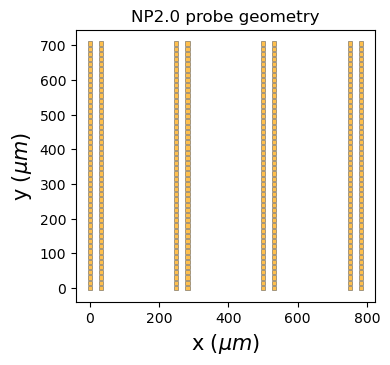

In [ ]:
fig, ax = plt.subplots(figsize=(4, 10))
si.plot_probe_map(recording, ax=ax, with_channel_ids=False)
ax.set_title('NP2.0 probe geometry')
plt.tight_layout() #TODO: color the used channels from the channel map data in the future

/tmp/ipykernel_695815/3128029155.py:6: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  si.plot_traces(


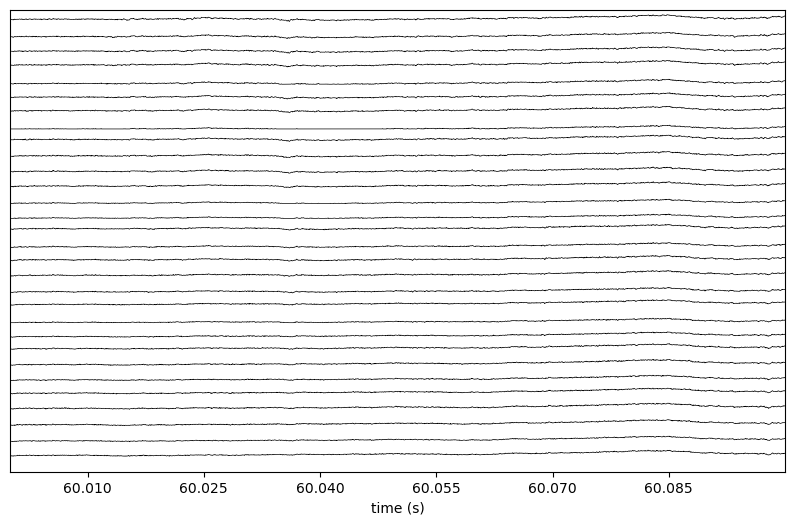

In [ ]:
t_start = 60.0  # seconds into session
t_end   = t_start + 0.1
ch_ids  = recording.channel_ids[50:80]  # channels near middle of shank

fig, ax = plt.subplots(figsize=(10, 6))
si.plot_traces(
    recording,
    time_range=(t_start, t_end),
    channel_ids=ch_ids,
    backend='matplotlib',
    ax=ax,
    mode='line',
    return_scaled=False,
)

for line in ax.get_lines():
    line.set_linewidth(0.5)

legend = ax.get_legend()
if legend is not None:
    legend.remove()